**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, CLASS_NAMES, load_fashion_mnist

set_seed()  

**Célula 2 – carregar e inspecionar:**

In [2]:
X_train, y_train, X_test, y_test = load_fashion_mnist()   

print("X_train:", X_train.shape, X_train.dtype)  
print("X_test: ", X_test.shape, X_test.dtype)
print("Valores dos píxeis: min =", X_train.min(), "| max =", X_train.max())
print("Labels possíveis:", np.unique(y_train))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 690kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 8.46MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.12MB/s]

X_train: (60000, 28, 28) uint8
X_test:  (10000, 28, 28) uint8
Valores dos píxeis: min = 0 | max = 255
Labels possíveis: [0 1 2 3 4 5 6 7 8 9]


**Célula 3 – contar imagens por classe:**

In [3]:
counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=10),  
    "test": np.bincount(y_test, minlength=10),
})
print(counts.to_string(index=False))

os.makedirs("results/tables", exist_ok=True)
counts.to_csv("results/tables/01_class_counts.csv", index=False) 

      class  train  test
T-shirt/top   6000  1000
    Trouser   6000  1000
   Pullover   6000  1000
      Dress   6000  1000
       Coat   6000  1000
     Sandal   6000  1000
      Shirt   6000  1000
    Sneaker   6000  1000
        Bag   6000  1000
 Ankle boot   6000  1000


**Célula 4 – grelha de exemplos (10 classes × 8 imagens):**

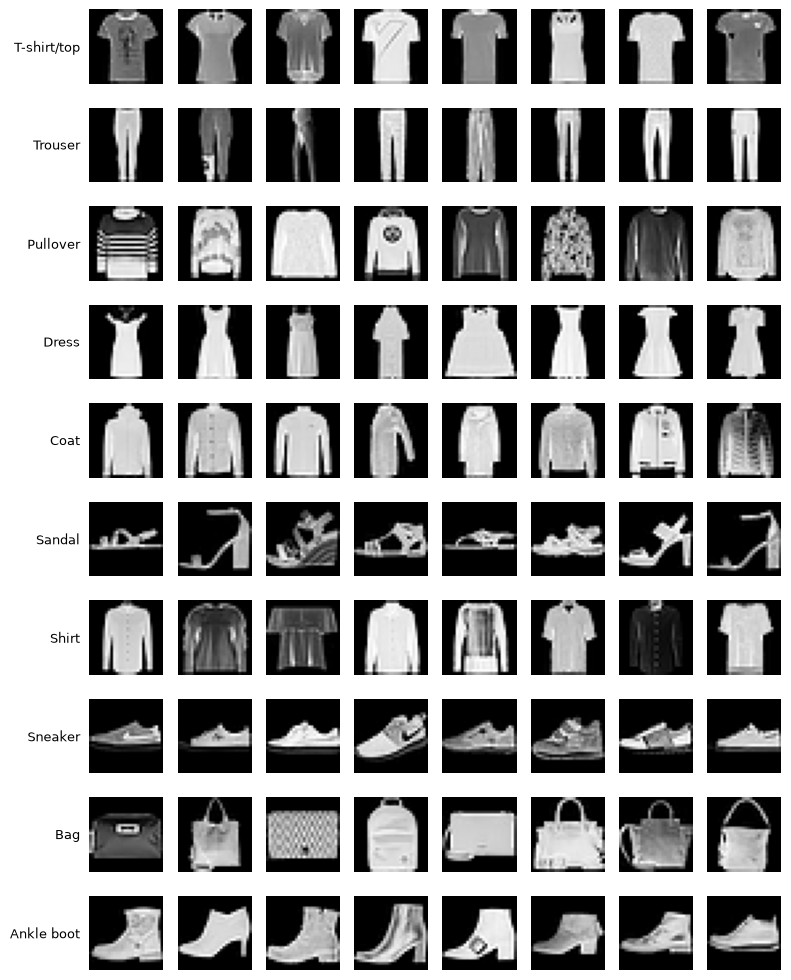

In [4]:
rng = np.random.default_rng(SEED) 
n_examples = 8

fig, axes = plt.subplots(10, n_examples, figsize=(n_examples, 10))
for c in range(10):
    idx_class = np.where(y_train == c)[0]                         
    chosen = rng.choice(idx_class, size=n_examples, replace=False) 
    for j, i in enumerate(chosen):
        ax = axes[c, j]
        ax.imshow(X_train[i], cmap="gray")   # mostra a imagem em tons de cinzento
        ax.axis("off")                       # esconde os eixos
    # escreve o nome da classe à esquerda da linha
    axes[c, 0].text(-4, 14, CLASS_NAMES[c], ha="right", va="center", fontsize=9)

plt.tight_layout()
os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/01_examples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()